# 9. Eigenvalues, Invariant Subspaces and the Minimal Polynomial
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Looking for eigenvectors. For each unit vector $v$ (grey dots) the arrow from $v$ to $Av$ is drawn, coloured by how much $A$ turns $v$. Eigenvectors are the directions in which $Av$ stays on the line through $v$ (red rays). Left, a symmetric matrix with two perpendicular eigen-directions. Middle, a shear with only one. Right, a rotation by $50^\circ$ composed with a stretch, which turns every direction: no real eigenvector.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


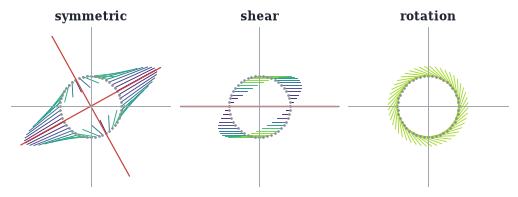

In [2]:
mats = [("symmetric", np.array([[2.0, 0.8], [0.8, 1.0]])), ("shear", np.array([[1.0, 0.9], [0.0, 1.0]])),
        ("rotation", 1.3 * np.array([[np.cos(0.87), -np.sin(0.87)], [np.sin(0.87), np.cos(0.87)]]))]
th = np.linspace(0, 2 * np.pi, 48, endpoint=False)
V = np.vstack([np.cos(th), np.sin(th)])
fig, axs = plt.subplots(1, 3, figsize=(W, 1.75))
for ax, (name, A) in zip(axs, mats):
    plane(ax, 2.6, grid=False)
    AV = A @ V
    turn = np.abs(np.arcsin(np.clip((V[0] * AV[1] - V[1] * AV[0]) / np.linalg.norm(AV, axis=0), -1, 1)))
    for k in range(V.shape[1]):
        ax.plot([V[0, k], AV[0, k]], [V[1, k], AV[1, k]], color=plt.cm.viridis(turn[k] / 1.0), lw=0.6)
    ax.plot(*V, ".", color=GRAY, ms=1.5)
    lam, X = np.linalg.eig(A)
    for l, x in zip(lam, X.T):
        if abs(l.imag) < 1e-12:
            x = np.real(x); ax.plot([-2.6 * x[0], 2.6 * x[0]], [-2.6 * x[1], 2.6 * x[1]], color=RED, lw=0.8)
    ax.set_title(name)

In [3]:
def minimal_polynomial(A, tol=1e-9):
    """Smallest m with I, A, ..., A^m dependent; returns monic coefficients (constant first)."""
    n = A.shape[0]
    powers = [np.eye(n).ravel()]
    P = np.eye(n)
    for m in range(1, n + 1):
        P = P @ A
        M = np.column_stack(powers)                       # columns vec(A^0), ..., vec(A^{m-1})
        c, *_ = np.linalg.lstsq(M, -P.ravel(), rcond=None)
        if np.linalg.norm(M @ c + P.ravel()) < tol * max(1, np.linalg.norm(P)):
            return np.r_[c, 1.0]
        powers.append(P.ravel())
T = np.zeros((5, 5)); T[1:, :4] = np.eye(4); T[0, 4], T[1, 4] = -3, 6
print("minimal polynomial of the companion matrix:", minimal_polynomial(T).round(10) + 0.0)
D = np.diag([2.0, 2.0, 3.0])                                 # repeated eigenvalue, diagonalizable
J = np.array([[2.0, 1, 0], [0, 2, 0], [0, 0, 3]])            # repeated eigenvalue, not diagonalizable
print("diag(2,2,3):", minimal_polynomial(D).round(10), "  -> (z-2)(z-3)")
print("Jordan-like:", minimal_polynomial(J).round(10), "  -> (z-2)^2 (z-3)")

minimal polynomial of the companion matrix: [ 3. -6.  0.  0.  0.  1.]
diag(2,2,3): [ 6. -5.  1.]   -> (z-2)(z-3)
Jordan-like: [-12.  16.  -7.   1.]   -> (z-2)^2 (z-3)


Orbits $x_{k+1}=Ax_k$ in the plane for six matrices, classified by their eigenvalues (shown). A sink (both $\lvert\lambda\rvert<1$) pulls everything in; a saddle stretches along one eigenvector and squeezes along the other; complex eigenvalues produce spirals (inward if $\lvert\lambda\rvert<1$, outward if $>1$) or closed ellipses (if $\lvert\lambda\rvert=1$); a shear-like matrix with a repeated eigenvalue has only one invariant line. Red lines: real eigenvectors.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


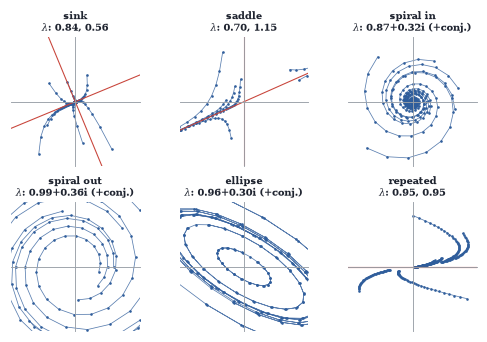

In [4]:
def rot(t, r): return r * np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
cases = [("sink", np.array([[0.8, 0.1], [0.1, 0.6]])), ("saddle", np.array([[1.15, 0.0], [0.2, 0.7]])),
         ("spiral in", rot(0.35, 0.93)), ("spiral out", rot(0.35, 1.05)),
         ("ellipse", np.array([[1, 1], [-1, 0.0]]) @ rot(0.3, 1.0) @ np.linalg.inv(np.array([[1, 1], [-1, 0.0]]))),
         ("repeated", np.array([[0.95, 0.12], [0.0, 0.95]]))]
fig, axs = plt.subplots(2, 3, figsize=(W, 3.0))
rng = np.random.default_rng(2)
for ax, (name, A) in zip(axs.ravel(), cases):
    plane(ax, 2.2, grid=False)
    for x0 in rng.uniform(-2, 2, size=(7, 2)):
        X = [x0]
        for _ in range(40):
            X.append(A @ X[-1])
        X = np.array(X); ax.plot(*X.T, "-", color=BLUE, lw=0.5, alpha=0.8); ax.plot(*X.T, ".", color=BLUE, ms=1.4)
    lam, V = np.linalg.eig(A)
    for l, v in zip(lam, V.T):
        if abs(l.imag) < 1e-9:
            v = np.real(v); ax.plot([-3 * v[0], 3 * v[0]], [-3 * v[1], 3 * v[1]], color=RED, lw=0.7)
    lab = ", ".join(f"{l.real:.2f}" if abs(l.imag) < 1e-9 else f"{l.real:.2f}{l.imag:+.2f}i" for l in lam[:2 if abs(lam[0].imag) < 1e-9 else 1])
    ax.set_title(f"{name}\n$\\lambda$: {lab}" + ("" if abs(lam[0].imag) < 1e-9 else " (+conj.)"), fontsize=6.3)

Power iteration for the Markov matrix $A$ with eigenvalues $1$ and $0.4$. Left, the iterates $A^kx_0$ from three starting distributions converge to the steady state $(1/3,2/3)$ along the line $x_1+x_2=1$. Right, the distance to the steady state falls like $0.4^k$ (dashed), a straight line on a log scale.

Text(0, 0.5, 'error')

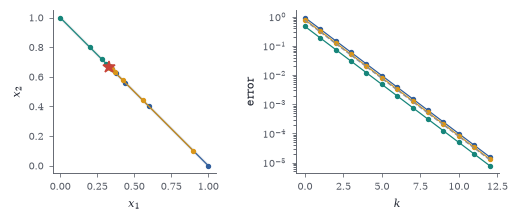

In [5]:
A = np.array([[0.6, 0.2], [0.4, 0.8]])
ss = np.array([1 / 3, 2 / 3])
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
axs[0].plot([0, 1], [1, 0], color=LIGHT, lw=2)
for x0, col in [((1, 0), BLUE), ((0, 1), TEAL), ((0.9, 0.1), GOLD)]:
    X = [np.array(x0, float)]
    for _ in range(12):
        X.append(A @ X[-1])
    X = np.array(X); axs[0].plot(*X.T, "o-", color=col, ms=2.5, lw=0.8)
    axs[1].semilogy(np.linalg.norm(X - ss, axis=1), "o-", color=col, ms=2.5, lw=0.8)
axs[0].plot(*ss, "*", color=RED, ms=8); axs[0].set_xlabel("$x_1$"); axs[0].set_ylabel("$x_2$"); axs[0].set_aspect("equal")
axs[1].semilogy(0.75 * 0.4 ** np.arange(13), "--", color=GRAY, lw=0.8); axs[1].set_xlabel("$k$"); axs[1].set_ylabel("error")

Eigenvalues of $200$ random $6\times6$ matrices with entries uniform in $[-1,1]$ (dots), inside the disc $\lvert\lambda\rvert\le n\max\lvert M_{jk}\rvert$ (outer circle) and the sharper row-sum disc for the matrix with the largest row sum (inner circle). The crude bound is valid but very pessimistic.

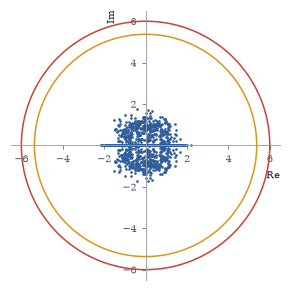

In [6]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(W * 0.55, W * 0.55))
complex_plane(ax, 6.5, ticks=True)
mx, rs = 0, 0
for _ in range(200):
    M = rng.uniform(-1, 1, size=(6, 6)); lam = np.linalg.eigvals(M)
    ax.plot(lam.real, lam.imag, ".", color=BLUE, ms=1.5); mx = max(mx, np.abs(M).max()); rs = max(rs, np.abs(M).sum(1).max())
th = np.linspace(0, 2 * np.pi, 300)
ax.plot(6 * mx * np.cos(th), 6 * mx * np.sin(th), color=RED, lw=1); ax.plot(rs * np.cos(th), rs * np.sin(th), color=GOLD, lw=1)

The function $\lambda\mapsto\dim\operatorname{range}(T-\lambda I)$ for a $4\times4$ matrix with eigenvalues $1,1,2,3$ (the eigenvalue $1$ having a one-dimensional eigenspace), shown together with the smallest singular value $\sigma_{\min}(T-\lambda I)$ along the real axis. The rank drops only at isolated points, but the smallest singular value, a continuous quantity, dips smoothly to zero there.

(-0.1, 4.5)

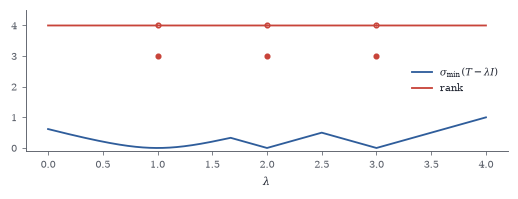

In [7]:
T = np.array([[1, 1, 0, 0], [0, 1, 0, 0], [0, 0, 2, 0], [0, 0, 0, 3.0]])
lam = np.linspace(0, 4, 2001)
rk = [np.linalg.matrix_rank(T - l * np.eye(4), tol=1e-9) for l in lam]
sm = [np.linalg.svd(T - l * np.eye(4), compute_uv=False)[-1] for l in lam]
fig, ax = plt.subplots(figsize=(W, 1.7))
ax.plot(lam, sm, color=BLUE, label=r"$\sigma_{\min}(T-\lambda I)$")
for e in [1, 2, 3]:
    ax.plot([e], [3], "o", color=RED, ms=3); ax.plot([e], [4], "o", mfc="white", mec=RED, ms=3)
ax.plot(lam, np.where(np.isin(np.round(lam, 6), [1, 2, 3]), np.nan, 4), color=RED, lw=1.2, label="rank")
ax.set_xlabel(r"$\lambda$"); ax.legend(loc="center right"); ax.set_ylim(-0.1, 4.5)

In [8]:
A = np.array([[0.6, 0.2], [0.4, 0.8]]); Ainf = np.array([[1, 1], [2, 2]]) / 3
print("eigenvalues of A:", np.linalg.eigvals(A))
for k in [1, 5, 10, 20, 40]:
    print(f"k={k:3d}   max |A^k - A_inf| = {np.abs(np.linalg.matrix_power(A, k) - Ainf).max():.2e}   0.4^k = {0.4**k:.2e}")

eigenvalues of A: [0.4 1. ]
k=  1   max |A^k - A_inf| = 2.67e-01   0.4^k = 4.00e-01
k=  5   max |A^k - A_inf| = 6.83e-03   0.4^k = 1.02e-02
k= 10   max |A^k - A_inf| = 6.99e-05   0.4^k = 1.05e-04
k= 20   max |A^k - A_inf| = 7.33e-09   0.4^k = 1.10e-08
k= 40   max |A^k - A_inf| = 1.22e-15   0.4^k = 1.21e-16
